# 01 · Proxy Model and Forecast Method

A full reservoir simulation is too slow to run thousands of times. This notebook builds a **proxy**: a fast ML model
that takes the 4 uncertain parameters of a case (Fault Transmissibility, Porosity Multiplier, Permeability Multiplier,
Aquifer Pore Volume) and returns its production curves. It also chooses how to forecast production after 2008.

**Inputs:** the case parameters (`dwc26/TestCases/01 Introduction.xlsx`) and the simulated curves prepared in
notebook 00 (`data/`).

The work has two parts:

1. **History proxy (1998 → 2008).** Parameters → simulated rates and cumulatives. The history matching in notebook 02
   calls this model thousands of times in place of the simulator.
2. **Forecast method (2008 → 2028).** The simulations stop at 2008-01-01, so there is no simulated data to train a
   forecast on. Two approaches are compared:
   - **Approach A: proxy + decline curves.** Fit standard decline curves (Arps for oil, exponential for total liquid)
     to the last few years of history and extend them. The curve shapes keep the forecast physically sensible.
   - **Approach B: GRU neural network.** A recurrent network that, given the parameters, steps production forward one
     quarter at a time up to 2028.

   To compare them fairly, every model is retrained on data up to 2006-01-01 and asked to forecast the hidden quarters
   2006-04 → 2008-01 (a **backtest**).

**Data split:** cases 1–70 for training, 71–85 for validation (choosing models and settings), 86–100 for testing
(reported once). No case is used in more than one split.

## 1. Setup

In [1]:
import re
import copy
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display
from scipy.optimize import curve_fit
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

warnings.filterwarnings('ignore', category=ConvergenceWarning)  # GP / MLP optimizer chatter

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()  # works from repo root or notebook/
DATA_DIR = ROOT / 'data'  # cleaned outputs of notebook 00
RAW_DIR = ROOT / 'dwc26' / 'TestCases'  # organiser's starter kit
TEMPLATE_PATH = RAW_DIR / '09 Template Deliverable.xlsx'  # official template
OUT_DIR = ROOT / 'outputs'
FIG_DIR = OUT_DIR / 'figures' / '01_Proxy_Model'  # one figure folder per notebook
MODEL_DIR = OUT_DIR / 'models'
for d in (FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

VARS = ['oil', 'gas', 'water']
RATE_COLS = ['Oil_production_rate_STB_d', 'Gas_production_rate_MSCF_d', 'Water_production_rate_STB_d']
CUM_COLS = ['Oil_production_cumulative_STB', 'Gas_production_cumulative_MSCF', 'Water_production_cumulative_STB']
CUM_UNITS = ['STB', 'MSCF', 'STB']
PARAM_COLS = ['Fault Transmissibility', 'Porosity Multiplier', 'Permeability Multiplier', 'Aquifer Pore Volume']

TRAIN_CASES = np.arange(1, 71)
VAL_CASES = np.arange(71, 86)
TEST_CASES = np.arange(86, 101)
ix = lambda cases: np.asarray(cases) - 1  # case number -> row index in the case-ordered arrays

# Chart styling: recessive grid/axes, thin lines, one fixed colour per entity across the notebook
C = {'actual': '#0b0b0b', 'A': '#2a78d6', 'B': '#eb6834', 'blend': '#1baf7a',
     'train': '#c3c2b7', 'val': '#6250d6', 'test': '#008300', 'muted': '#898781'}
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.labelcolor': '#52514e', 'xtick.color': '#898781', 'ytick.color': '#898781',
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'legend.frameon': False,
    'font.size': 9.5, 'lines.linewidth': 2,
})


def savefig(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')


print('torch', torch.__version__)

torch 2.14.1+cpu


## 2. Load the prepared data

- **Inputs (X):** the 4 parameters of each case. The permeability multiplier spans about 1–10×, so it is used on a log
  scale.
- **Targets (Y):** quarterly oil, gas and water rates and cumulatives at 41 dates, 1998-01-01 → 2008-01-01, for each
  case.
- The curve files also contain a column labelled `UNKNOWN_COL_101`. It is the observed field history, not a simulated
  case, so it is left out here. Notebook 02 uses it as the history-matching target.
- The official template (`dwc26/TestCases/09 Template Deliverable.xlsx`) is read to confirm the forecast dates,
  2008-04-01 → 2028-01-01.

In [2]:
def case_number(label):
    return int(re.search(r'\d+', str(label)).group())


params = pd.read_excel(RAW_DIR / '01 Introduction.xlsx', sheet_name='Uncertainty Values')
params.index = params['Item'].map(case_number)
params = params[PARAM_COLS].sort_index()
params.index.name = 'case'


def load_curves(path, cols):
    df = pd.read_excel(path)
    df = df[df['Case'].str.startswith('CASE')].copy()
    df['case'] = df['Case'].map(case_number)
    cube = np.stack([df.pivot(index='case', columns='Date', values=c).sort_index().to_numpy(float) for c in cols], axis=-1)
    dates = pd.DatetimeIndex(sorted(df['Date'].unique()))
    cases = np.sort(df['case'].unique())
    return cube, dates, cases


RATE, HIST_DATES, rate_cases = load_curves(DATA_DIR / 'Simulation_Rates_Consolidated.xlsx', RATE_COLS)
CUM, cum_dates, cum_cases = load_curves(DATA_DIR / 'Simulation_Cumulatives_Consolidated.xlsx', CUM_COLS)
assert (rate_cases == np.arange(1, 101)).all() and (cum_cases == rate_cases).all()
assert HIST_DATES.equals(cum_dates) and (params.index == rate_cases).all()

# Template: 10 sheets, quarterly cumulatives from 2008-04-01 to 2028-01-01
template = pd.read_excel(TEMPLATE_PATH, sheet_name=None)
TEMPLATE_COLS = list(next(iter(template.values())).columns)
FC_DATES = pd.date_range('2008-04-01', '2028-01-01', freq='QS-JAN')
tmpl_dates = pd.to_datetime(template['Case 2']['Date'], format='mixed')
assert pd.DatetimeIndex(tmpl_dates).equals(FC_DATES), 'forecast dates do not match the template'

print(f'Params: {params.shape} | RATE/CUM cubes: {RATE.shape} (cases, dates, [oil, gas, water])')
print(f'History: {HIST_DATES[0].date()} → {HIST_DATES[-1].date()} ({len(HIST_DATES)} quarters)')
print(f'Forecast: {FC_DATES[0].date()} → {FC_DATES[-1].date()} ({len(FC_DATES)} quarters)')
print('Template columns:', TEMPLATE_COLS)
print('Template sheet lengths:', {k: len(v) for k, v in template.items()})
display(params.describe().T.round(3))

Params: (100, 4) | RATE/CUM cubes: (100, 41, 3) (cases, dates, [oil, gas, water])
History: 1998-01-01 → 2008-01-01 (41 quarters)
Forecast: 2008-04-01 → 2028-01-01 (80 quarters)
Template columns: ['Date', 'Gas production cumulative [MSCF]', 'Oil production cumulative [STB]', 'Water production cumulative [STB]']
Template sheet lengths: {'Case 1': 80, 'Case 2': 80, 'Case 3': 80, 'Case 4': 80, 'Case 5': 80, 'Case 6': 80, 'Case 7': 80, 'Case 8': 80, 'Case 9': 80, 'Case 10': 80}


,count,mean,std,min,25%,50%,75%,max
Fault Transmissibility,100.0,0.100,0.030,0.050,0.075,0.099,0.127,0.150
Porosity Multiplier,100.0,1.148,0.204,0.801,0.977,1.145,1.348,1.494
Permeability Multiplier,100.0,5.200,2.727,0.521,2.778,5.309,7.535,9.785
Aquifer Pore Volume,100.0,125.166,42.370,53.953,89.848,125.772,159.660,199.835


## 3. Data checks that guide the model design

In [3]:
T0 = int(np.argmax(RATE[:, :, 0].max(axis=0) > 0))  # first producing quarter
prod = slice(T0, None)
gor = RATE[:, prod, 1] / RATE[:, prod, 0]
liquid = RATE[:, :, 0] + RATE[:, :, 2]
print(f'First production in the curves: {HIST_DATES[T0].date()}')
print(f'GOR (gas/oil rate) across all cases and quarters: {gor.min():.4f} – {gor.max():.4f} MSCF/STB  → gas ≈ constant × oil')
print(f'Liquid rate spread across cases (max/min per quarter): {np.nanmax(liquid[:, prod].max(0) / liquid[:, prod].min(0)):.3f}')

# Cumulative-from-rate convention: rate at date t is the rate over the *preceding* quarter (right-point rule)
days_hist = np.diff(HIST_DATES.values).astype('timedelta64[D]').astype(float)
inc = np.diff(CUM[ix(TRAIN_CASES)], axis=1)
right = RATE[ix(TRAIN_CASES), 1:] * days_hist[None, :, None]
late = slice(-12, None)  # last 3 years, i.e. the declining regime the forecast continues from
CUM_CORR = np.nanmedian((inc[:, late] / right[:, late]).reshape(-1, 3), axis=0)
print('Right-point integration correction (actual Δcum / rate·days, late history, train cases):',
      dict(zip(VARS, CUM_CORR.round(4))))

# Parameter sensitivity of 2008 cumulatives (Spearman, train cases only)
final = pd.DataFrame(CUM[ix(TRAIN_CASES), -1], columns=[f'{v} cum 2008' for v in VARS], index=TRAIN_CASES)
sens = pd.concat([params.loc[TRAIN_CASES], final], axis=1).corr(method='spearman').loc[PARAM_COLS, final.columns]
display(sens.round(2))

First production in the curves: 1999-01-01
GOR (gas/oil rate) across all cases and quarters: 0.3602 – 0.3652 MSCF/STB  → gas ≈ constant × oil
Liquid rate spread across cases (max/min per quarter): 1.107
Right-point integration correction (actual Δcum / rate·days, late history, train cases): {'oil': np.float64(1.007), 'gas': np.float64(1.0071), 'water': np.float64(0.9961)}


,oil cum 2008,gas cum 2008,water cum 2008
Fault Transmissibility,0.20,0.20,-0.20
Porosity Multiplier,0.99,0.99,-0.99
Permeability Multiplier,0.00,0.00,0.09
Aquifer Pore Volume,-0.22,-0.22,0.29


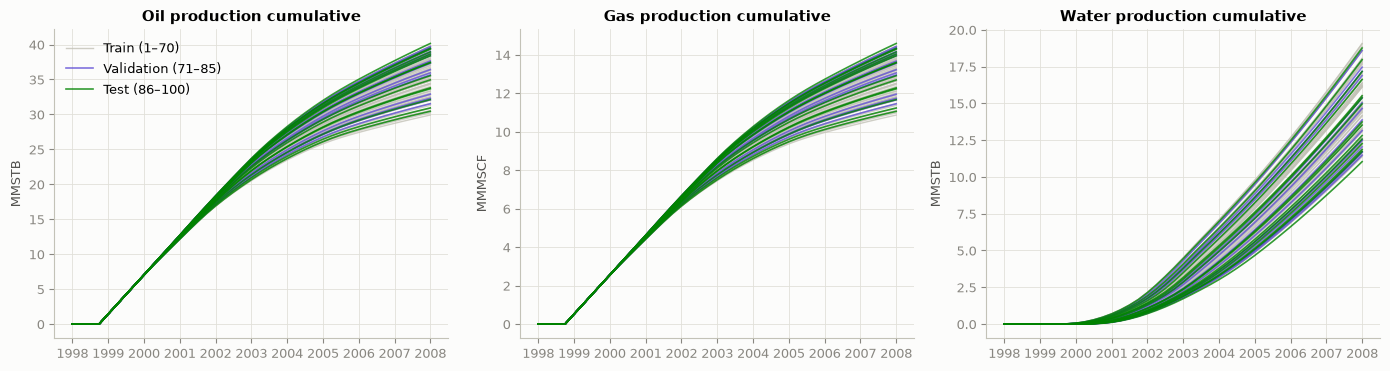

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for v, ax in enumerate(axes):
    for cases, key, label in [(TRAIN_CASES, 'train', 'Train (1–70)'), (VAL_CASES, 'val', 'Validation (71–85)'),
                              (TEST_CASES, 'test', 'Test (86–100)')]:
        for j, c in enumerate(cases):
            ax.plot(HIST_DATES, CUM[c - 1, :, v] / 1e6, color=C[key], lw=1 if key == 'train' else 1.2,
                    alpha=0.8, label=label if j == 0 else None)
    ax.set_title(f'{VARS[v].title()} production cumulative')
    ax.set_ylabel(f'MM{CUM_UNITS[v]}')
axes[0].legend(loc='upper left')
fig.tight_layout()
savefig(fig, '01_history_curves_by_split')
plt.show()

**What it shows:** The simulated oil, gas and water cumulatives from 1998 to 2008 for all 100 cases, coloured by
data split (training, validation, test).

**Findings:**
- Every case starts producing at 1999-01-01, and the cases are almost the same until about 2002. They spread apart
  after that.
- By 2008, oil ranges from about 30 to 40 MMSTB and water from about 11 to 19 MMSTB.
- Validation and test cases lie inside the range of the training cases, so the proxy is never asked to go beyond what
  it was trained on.
- Gas has exactly the same shape as oil, because the gas/oil ratio is constant.

**Findings from the checks above**

- **Gas adds no extra information.** The gas/oil ratio (GOR) is constant, about 0.36 MSCF/STB, in every case and
  quarter. The reservoir stays above its bubble point (gas saturation is 0 in all grid blocks), so gas rate = GOR × oil
  rate.
- **Total liquid rate follows the well-control schedule** and is nearly the same in every case. The parameters change
  how that liquid splits between oil and water (the water cut), and how fast liquid declines at the end.
- **Rates are averages over the quarter that ends at each date.** Cumulatives are rebuilt from rates with this rule
  plus a small calibrated correction (`CUM_CORR`).
- **Porosity drives both oil and water.** Across the training cases, higher porosity means more oil and less water by
  2008 (rank correlation +0.99 and −0.99). The other three parameters have much smaller effects (see the tornado chart
  in Section 5).

With only 70 training cases, a small, smooth model on the 4 case parameters is the right choice. The 3-million-row
grid files from notebook 00 repeat the same 70 cases block by block, so they add no new independent samples for a
field-level model.

## 4. Feature preparation

In [5]:
def make_features(p):
    X = p[PARAM_COLS].to_numpy(float).copy()
    X[:, 2] = np.log(X[:, 2])  # permeability multiplier ~1–10× → log scale
    return X


x_scaler = StandardScaler().fit(make_features(params.loc[TRAIN_CASES]))
X = x_scaler.transform(make_features(params))  # (100, 4), scaler fitted on train only

## 5. History proxy: parameters → 1998–2008 curves

Each case's 6 curves × 41 quarters are joined into one vector (246 values). Each curve type is scaled by its own
spread, and **PCA** compresses the vectors into a few components. A regression model maps the 4 parameters to these
components, and reversing the PCA gives the full, smooth set of curves in one step. A small post-processing step keeps
the results physical: rates ≥ 0 and cumulatives never decreasing.

Three regression models are compared on the validation cases:
- **Ridge on cubic polynomial features**: a simple, transparent baseline (a classic response surface).
- **Gaussian Process** (Matérn-5/2 kernel, one length scale per parameter): the standard proxy for small designed
  experiments. It also shows how relevant each parameter is.
- **MLP ensemble**: a small neural network (average of 5 seeds) as the deep-learning option.

In [6]:
def pack(rate, cum, t_end):
    n = len(rate)
    return np.concatenate([cum[:, :t_end + 1].reshape(n, -1), rate[:, :t_end + 1].reshape(n, -1)], axis=1)


def unpack(Y, t_end):
    n, T = len(Y), t_end + 1
    cum = Y[:, :T * 3].reshape(n, T, 3)
    rate = np.clip(Y[:, T * 3:].reshape(n, T, 3), 0, None)
    cum = np.maximum.accumulate(np.clip(cum, 0, None), axis=1)
    return rate, cum


class CurveProxy:
    """Parameters → quarterly rate & cumulative curves via block-scaled PCA + a regressor on the PCA scores."""

    def __init__(self, make_model, per_component, var_kept=0.99999):
        self.make_model, self.per_component, self.var_kept = make_model, per_component, var_kept

    def fit(self, X, rate, cum, t_end):
        self.t_end = t_end
        Y = pack(rate, cum, t_end)
        self.mu = Y.mean(axis=0)
        Yc = Y - self.mu
        T = t_end + 1
        block = np.concatenate([np.tile(np.arange(3), T), 3 + np.tile(np.arange(3), T)])  # cum o/g/w, rate o/g/w
        self.scale = np.ones(Y.shape[1])
        for b in range(6):
            self.scale[block == b] = np.sqrt((Yc[:, block == b] ** 2).mean())
        self.pca = PCA(n_components=self.var_kept, svd_solver='full').fit(Yc / self.scale)
        S = self.pca.transform(Yc / self.scale)
        if self.per_component:
            self.models = [self.make_model().fit(X, S[:, k]) for k in range(S.shape[1])]
        else:
            self.models = [self.make_model().fit(X, S)]
        return self

    def predict(self, X):
        S = (np.column_stack([m.predict(X) for m in self.models]) if self.per_component
             else self.models[0].predict(X))
        return unpack(self.pca.inverse_transform(S) * self.scale + self.mu, self.t_end)


def make_ridge():
    return make_pipeline(PolynomialFeatures(3), RidgeCV(alphas=np.logspace(-6, 3, 40)))


def make_gp():
    kernel = (ConstantKernel(1.0, (1e-3, 1e3))
              * Matern(length_scale=np.ones(4), length_scale_bounds=(1e-2, 1e3), nu=2.5)
              + WhiteKernel(1e-5, (1e-10, 1e-1)))
    return GaussianProcessRegressor(kernel, normalize_y=True, n_restarts_optimizer=4, random_state=SEED)


class MLPEnsemble:
    def __init__(self, n_members=5):
        self.n_members = n_members

    def fit(self, X, S):
        self.sc = StandardScaler().fit(S)
        self.members = [MLPRegressor(hidden_layer_sizes=(32, 32), activation='tanh', solver='lbfgs', alpha=1e-2, max_iter=5000,
                                     random_state=SEED + i).fit(X, self.sc.transform(S))
                        for i in range(self.n_members)]
        return self

    def predict(self, X):
        return self.sc.inverse_transform(np.mean([m.predict(X) for m in self.members], axis=0))


HIST_MODELS = {
    'Ridge (cubic poly)': (make_ridge, False),
    'Gaussian Process': (make_gp, True),
    'MLP ensemble (NN)': (MLPEnsemble, False),
}


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


def curve_metrics(rate_true, cum_true, rate_pred, cum_pred):
    """Per-variable error metrics; normalised so oil/gas/water are comparable."""
    rows = {}
    for v, name in enumerate(VARS):
        ct, cp = cum_true[..., v], cum_pred[..., v]
        rt, rp = rate_true[..., v], rate_pred[..., v]
        rows[name] = {
            'Final cum APE %': 100 * np.mean(np.abs(cp[:, -1] - ct[:, -1]) / ct[:, -1]),
            'Final cum R²': r2_score(ct[:, -1], cp[:, -1]),
            'Cum NRMSE %': 100 * rmse(ct, cp) / ct[:, -1].mean(),
            'Rate NRMSE %': 100 * rmse(rt, rp) / rt.max(axis=1).mean(),
        }
    return pd.DataFrame(rows).T


T_END = len(HIST_DATES) - 1
hist_proxies, val_tables = {}, {}
for name, (factory, per_comp) in HIST_MODELS.items():
    proxy = CurveProxy(factory, per_comp).fit(X[ix(TRAIN_CASES)], RATE[ix(TRAIN_CASES)], CUM[ix(TRAIN_CASES)], T_END)
    r_pred, c_pred = proxy.predict(X[ix(VAL_CASES)])
    val_tables[name] = curve_metrics(RATE[ix(VAL_CASES)], CUM[ix(VAL_CASES)], r_pred, c_pred)
    hist_proxies[name] = proxy
print(f'PCA components kept: {hist_proxies["Gaussian Process"].pca.n_components_}')
print('Validation cases (71–85):')
display(pd.concat(val_tables).round(3))

PCA components kept: 24
Validation cases (71–85):


Final cum APE %  Final cum R²  Cum NRMSE %  \
Ridge (cubic poly) oil              0.108         0.999        0.102   
                   gas              0.107         0.999        0.101   
                   water            0.450         0.998        0.249   
Gaussian Process   oil              0.023         1.000        0.024   
                   gas              0.023         1.000        0.022   
                   water            0.113         1.000        0.063   
MLP ensemble (NN)  oil              0.985         0.977        0.603   
                   gas              0.985         0.977        0.604   
                   water            2.292         0.973        1.348   

                          Rate NRMSE %  
Ridge (cubic poly) oil           0.645  
                   gas           0.616  
                   water         1.368  
Gaussian Process   oil           0.126  
                   gas           0.111  
                   water         0.174  
MLP ensemble (NN)  oil           0.935  
                   gas           0.933  
                   water         1.682

In [7]:
# Select on validation (mean of cum + rate NRMSE across oil/gas/water), then report test once
score = {k: t[['Cum NRMSE %', 'Rate NRMSE %']].to_numpy().mean() for k, t in val_tables.items()}
BEST_HIST = min(score, key=score.get)
print('Validation score (lower is better):', {k: round(v, 3) for k, v in score.items()})
print(f'Selected history proxy: {BEST_HIST}')

test_tables = {}
for name, proxy in hist_proxies.items():
    r_pred, c_pred = proxy.predict(X[ix(TEST_CASES)])
    test_tables[name] = curve_metrics(RATE[ix(TEST_CASES)], CUM[ix(TEST_CASES)], r_pred, c_pred)
print('Test cases (86–100), reported for all models for transparency; the selection above used validation only:')
display(pd.concat(test_tables).round(3))

hist_proxy = hist_proxies[BEST_HIST]
_ = joblib.dump({'proxy': hist_proxy, 'x_scaler': x_scaler, 'param_cols': PARAM_COLS},
            MODEL_DIR / 'history_proxy.joblib')

Validation score (lower is better): {'Ridge (cubic poly)': np.float64(0.514), 'Gaussian Process': np.float64(0.087), 'MLP ensemble (NN)': np.float64(1.018)}
Selected history proxy: Gaussian Process
Test cases (86–100), reported for all models for transparency; the selection above used validation only:


Final cum APE %  Final cum R²  Cum NRMSE %  \
Ridge (cubic poly) oil              0.126         0.999        0.126   
                   gas              0.128         0.999        0.119   
                   water            0.311         0.999        0.254   
Gaussian Process   oil              0.026         1.000        0.036   
                   gas              0.025         1.000        0.035   
                   water            0.104         1.000        0.135   
MLP ensemble (NN)  oil              0.929         0.978        0.678   
                   gas              0.931         0.978        0.678   
                   water            1.703         0.981        1.189   

                          Rate NRMSE %  
Ridge (cubic poly) oil           0.732  
                   gas           0.673  
                   water         1.125  
Gaussian Process   oil           0.198  
                   gas           0.190  
                   water         0.363  
MLP ensemble (NN)  oil           1.039  
                   gas           1.031  
                   water         1.563

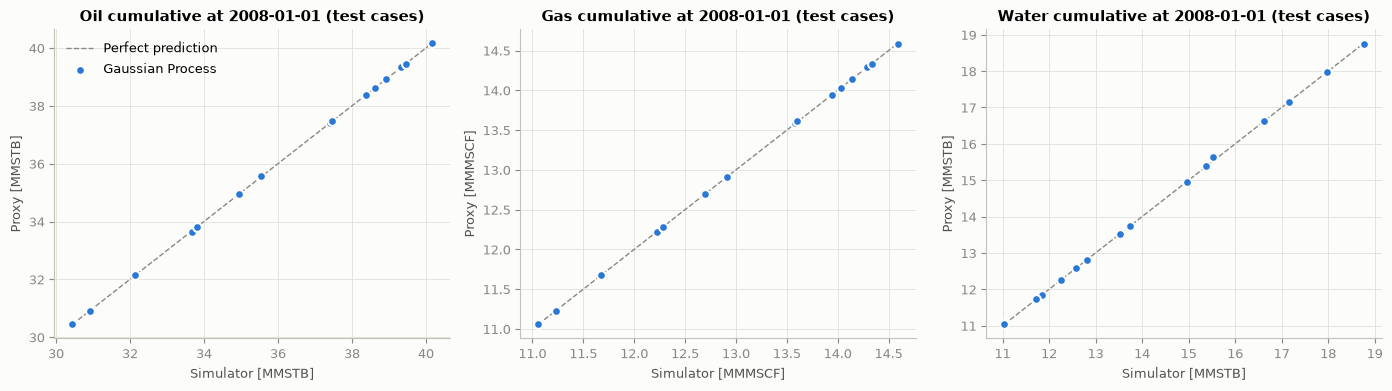

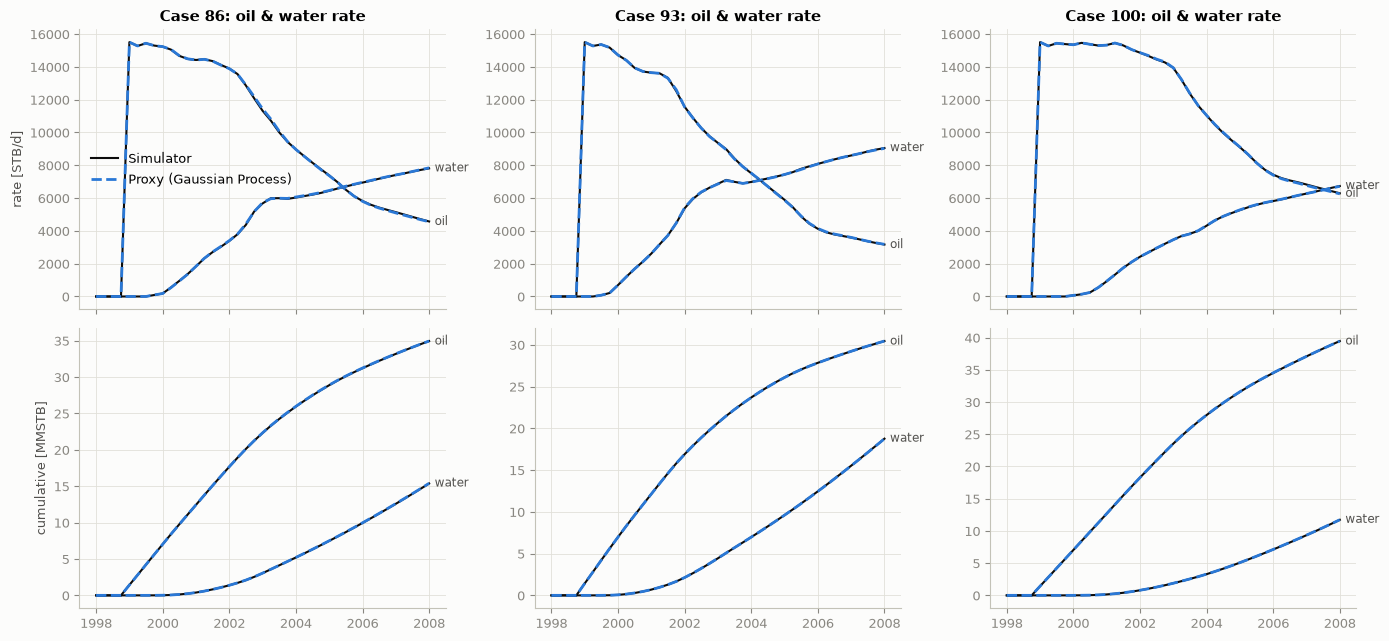

In [8]:
r_test, c_test = hist_proxy.predict(X[ix(TEST_CASES)])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for v, ax in enumerate(axes):
    t, p = CUM[ix(TEST_CASES), -1, v] / 1e6, c_test[:, -1, v] / 1e6
    lo, hi = min(t.min(), p.min()), max(t.max(), p.max())
    ax.plot([lo, hi], [lo, hi], color=C['muted'], lw=1, ls='--', label='Perfect prediction')
    ax.scatter(t, p, s=40, color=C['A'], edgecolor='#fcfcfb', linewidth=1.5, zorder=3, label=f'{BEST_HIST}')
    ax.set_title(f'{VARS[v].title()} cumulative at 2008-01-01 (test cases)')
    ax.set_xlabel(f'Simulator [MM{CUM_UNITS[v]}]')
    ax.set_ylabel(f'Proxy [MM{CUM_UNITS[v]}]')
axes[0].legend(loc='upper left')
fig.tight_layout()
savefig(fig, '02_history_proxy_parity_test')
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharex=True)
show = TEST_CASES[[0, 7, 14]]
for col, case in enumerate(show):
    k = list(TEST_CASES).index(case)
    for row, (arr, pred, lab) in enumerate([(RATE, r_test, 'rate [STB/d]'), (CUM, c_test, 'cumulative [MMSTB]')]):
        ax = axes[row, col]
        scale = 1 if row == 0 else 1e6
        for v, ls in [(0, '-'), (2, '-')]:
            ax.plot(HIST_DATES, arr[case - 1, :, v] / scale, color=C['actual'], lw=1.5,
                    label='Simulator' if v == 0 else None)
            ax.plot(HIST_DATES, pred[k, :, v] / scale, color=C['A'], ls='--', lw=2,
                    label=f'Proxy ({BEST_HIST})' if v == 0 else None)
            ax.annotate(VARS[v], (HIST_DATES[-1], arr[case - 1, -1, v] / scale), xytext=(4, 0),
                        textcoords='offset points', color='#52514e', fontsize=8.5, va='center')
        ax.set_title(f'Case {case}: oil & water {lab.split(" ")[0]}' if row == 0 else '')
        ax.set_ylabel(f'{lab}' if col == 0 else '')
axes[0, 0].legend(loc='center left')
for ax in axes[1]:
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout()
savefig(fig, '03_history_proxy_examples_test')
plt.show()

**What it shows:** First chart: for the 15 test cases the proxy never saw, the simulator's 2008 cumulative (x-axis) against
the proxy's prediction (y-axis). Points on the dashed line are perfect predictions. Second chart: the full 1998–2008 oil and
water curves of three test cases, simulator (black) against proxy (blue dashed).

**Findings:**
- Every test point sits on the line, for oil, gas and water.
- The average error on 2008 cumulatives is 0.03 % for oil and gas and 0.10 % for water.
- The Gaussian Process is the clear winner: its validation score (0.087) is about 6× better than Ridge (0.514) and 12×
  better than the neural network (1.018).
- The proxy also follows the curves over time, including the start-up jump, the plateau and every change in trend.

### Sensitivity of the results to each parameter (tornado chart)

With the proxy, sensitivity is cheap to compute: hold three parameters at their median and move the fourth from its
P10 to its P90 value. This shows which parameters drive recovery, and which ones the history matching in notebook 02
is likely to pin down.

,"oil (P10→P90 swing, MMSTB)","water (P10→P90 swing, MMSTB)"
Fault Transmissibility,-0.005,0.002
Porosity Multiplier,7.410,-6.101
Permeability Multiplier,0.931,-0.073
Aquifer Pore Volume,-0.054,0.480


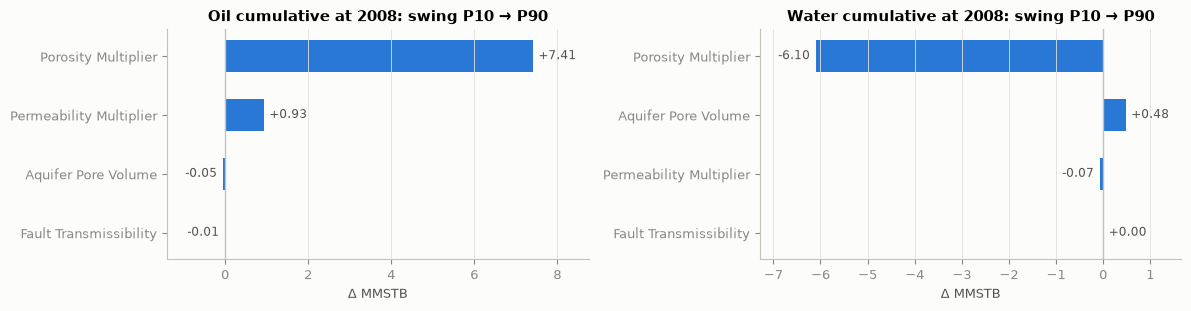

In [9]:
p10, p50, p90 = (params.loc[TRAIN_CASES].quantile(q) for q in (0.1, 0.5, 0.9))
tornado = {}
for col in PARAM_COLS:
    lohi = pd.DataFrame([p50, p50])
    lohi[col] = [p10[col], p90[col]]
    _, c = hist_proxy.predict(x_scaler.transform(make_features(lohi)))
    tornado[col] = {f'{VARS[v]} (P10→P90 swing, MM{CUM_UNITS[v]})': (c[1, -1, v] - c[0, -1, v]) / 1e6 for v in (0, 2)}
tornado = pd.DataFrame(tornado).T
display(tornado.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, (colname, v) in zip(axes, [(tornado.columns[0], 0), (tornado.columns[1], 2)]):
    s = tornado[colname].reindex(tornado[colname].abs().sort_values().index)
    ax.barh(s.index, s.values, color=C['A'], height=0.55)
    ax.axvline(0, color='#c3c2b7', lw=1)
    for y, val in enumerate(s.values):
        ax.annotate(f'{val:+.2f}', (val, y), xytext=(4 if val >= 0 else -4, 0), textcoords='offset points',
                    ha='left' if val >= 0 else 'right', va='center', fontsize=8.5, color='#52514e')
    ax.margins(x=0.18)  # room for value labels on both sides
    ax.set_title(f'{VARS[v].title()} cumulative at 2008: swing P10 → P90')
    ax.set_xlabel(f'Δ MM{CUM_UNITS[v]}')
    ax.grid(axis='y', visible=False)
fig.tight_layout()
savefig(fig, '04_sensitivity_tornado')
plt.show()

**What it shows:** How much the 2008 oil and water cumulatives change when one parameter moves from its P10 to its
P90 value, with the other three held at their median. A longer bar means a bigger effect.

**Findings:**
- **Porosity has by far the biggest effect:** +7.41 MMSTB oil and −6.10 MMSTB water.
- Permeability comes second for oil (+0.93 MMSTB) and aquifer size second for water (+0.48 MMSTB).
- Fault transmissibility has almost no effect (0.01 MMSTB or less). The production history cannot tell us its value,
  but it also matters very little for the forecast.

## 6. Forecast approaches (2008 → 2028)

### Approach A: decline-curve extrapolation
For each case, using the last `window` quarters of history:
- **Oil rate:** Arps hyperbolic decline $q(t) = q_i / (1 + b D_i t)^{1/b}$, with $0 < b \le 1$.
- **Total liquid rate:** exponential decline (allowing at most a slight increase).
- **Water** = liquid − oil (≥ 0); **gas** = the case's last GOR × oil.
- Both curves are anchored to the last historical rate for continuity. Cumulatives use the right-point rule with `CUM_CORR`.

For a *new parameter set* (as the optimizer will produce), the history comes from the history proxy, so the full
chain is **params → history proxy → decline fit → forecast**.

In [10]:
def integrate_cum(rate_fc, cum_anchor, anchor_date, fc_dates):
    """Right-point integration of forecast rates (rate at t = average over the preceding period)."""
    days = np.diff(pd.DatetimeIndex([anchor_date]).append(pd.DatetimeIndex(fc_dates)).values).astype('timedelta64[D]').astype(float)
    return cum_anchor[:, None, :] + np.cumsum(rate_fc * days[None, :, None] * CUM_CORR, axis=1)


def _log_arps(t, log_qi, log_di, b):
    return log_qi - np.log1p(b * np.exp(log_di) * t) / b


def decline_forecast(rate_hist, cum_hist, hist_dates, fc_dates, window=8):
    """Approach A. rate_hist/cum_hist: (n, T, 3) history ending at hist_dates[-1]. Returns (rate_fc, cum_fc, fit_params)."""
    anchor = hist_dates[-1]
    t_hist = np.asarray((hist_dates - anchor).days, float) / 365.25
    t_fc = np.asarray((pd.DatetimeIndex(fc_dates) - anchor).days, float) / 365.25
    w = slice(len(hist_dates) - window, None)
    tw = t_hist[w] - t_hist[w][0]
    rate_fc = np.zeros((len(rate_hist), len(fc_dates), 3))
    fits = []
    for i in range(len(rate_hist)):
        qo, qw = rate_hist[i, :, 0], rate_hist[i, :, 2]
        ql = qo + qw
        (lqi, ldi, b), _ = curve_fit(_log_arps, tw, np.log(np.clip(qo[w], 1.0, None)),
                                     p0=(np.log(qo[w][0]), np.log(0.1), 0.5),
                                     bounds=([-np.inf, np.log(1e-4), 1e-3], [np.inf, np.log(5.0), 1.0]), maxfev=20000)
        shift = -t_hist[w][0]  # anchor date expressed in window time
        qo_fc = qo[-1] * np.exp(_log_arps(t_fc + shift, lqi, ldi, b) - _log_arps(shift, lqi, ldi, b))
        dl = float(np.clip(-np.polyfit(tw, np.log(ql[w]), 1)[0], -0.02, 1.0))
        ql_fc = ql[-1] * np.exp(-dl * t_fc)
        qo_fc = np.minimum(qo_fc, ql_fc)
        last_gor = rate_hist[i, -1, 1] / max(qo[-1], 1e-9)
        rate_fc[i] = np.stack([qo_fc, last_gor * qo_fc, ql_fc - qo_fc], axis=-1)
        fits.append({'oil_Di_per_yr': np.exp(ldi), 'oil_b': b, 'liquid_D_per_yr': dl, 'GOR': last_gor})
    return rate_fc, integrate_cum(rate_fc, cum_hist[:, -1], anchor, fc_dates), pd.DataFrame(fits)

### Approach B: GRU neural network

Each quarter, the reservoir state is `[log liquid rate, logit water cut, Np, Wp]` (normalised; Np and Wp are the
cumulative oil and water). Given the 4 parameters and the current state, a GRU cell predicts the *change* in liquid
rate and water cut. Oil and water rates follow from these, and the cumulatives are added up inside the network. This
keeps outputs positive, water cut between 0 and 1, and cumulatives increasing. Gas = GOR × oil.

Training mixes two modes, so one network covers both uses:
- **Full run from first production** (parameters only): a complete parameters → curves proxy.
- **Continuation:** fed the true history up to a random quarter, then run on its own.

The loss is the mean squared error on normalised oil and water rates and cumulatives over the steps the network runs
on its own. Training stops early based on the validation cases. The final prediction averages 5 seeds.

In [11]:
TRAIN_IDX = ix(TRAIN_CASES)
Q_SCALE = float(RATE[TRAIN_IDX, :, 0].max())
NP_SCALE = float(CUM[TRAIN_IDX, -1, 0].mean())
WP_SCALE = float(CUM[TRAIN_IDX, -1, 2].mean())
GOR_TRAIN = float(np.median(RATE[TRAIN_IDX, T0:, 1] / RATE[TRAIN_IDX, T0:, 0]))
_lql = np.log(RATE[TRAIN_IDX, T0:, 0] + RATE[TRAIN_IDX, T0:, 2])
LQL_MU, LQL_SD = float(_lql.mean()), float(_lql.std())
WC_CLIP, LOGIT_SCALE = 1e-3, 4.0
CORR_T = torch.tensor(CUM_CORR, dtype=torch.float32)


def to_state(rate, cum):
    qo, qw = rate[..., 0], rate[..., 2]
    ql = np.clip(qo + qw, 1.0, None)
    wc = np.clip(qw / ql, WC_CLIP, 1 - WC_CLIP)
    return np.stack([(np.log(ql) - LQL_MU) / LQL_SD, np.log(wc / (1 - wc)) / LOGIT_SCALE,
                     cum[..., 0] / NP_SCALE, cum[..., 2] / WP_SCALE], axis=-1).astype(np.float32)


def state_rates(s):
    ql = torch.exp(s[..., 0] * LQL_SD + LQL_MU)
    wc = torch.sigmoid(s[..., 1] * LOGIT_SCALE)
    return ql * (1 - wc), ql * wc


def state_obs(s):
    qo, qw = state_rates(s)
    return torch.stack([qo / Q_SCALE, qw / Q_SCALE, s[..., 2], s[..., 3]], dim=-1)


class ReservoirGRU(nn.Module):
    def __init__(self, n_static=4, n_state=4, hidden=48):
        super().__init__()
        self.init_h = nn.Sequential(nn.Linear(n_static, hidden), nn.Tanh())
        self.cell = nn.GRUCell(n_static + n_state, hidden)
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, 2))
        nn.init.zeros_(self.head[-1].weight)  # start as "no change" for stable early training
        nn.init.zeros_(self.head[-1].bias)

    def forward(self, x, s0, days, teacher=None, n_teacher=0):
        """x: (B,4) params; s0: (B,4) state at first step; days: (K,) step lengths.
        Teacher-forced for the first n_teacher steps, free-running after. Returns states (B, K+1, 4)."""
        h, s, out = self.init_h(x), s0, [s0]
        for k in range(len(days)):
            h = self.cell(torch.cat([x, s], dim=1), h)
            d = self.head(h)
            nxt = torch.stack([s[:, 0] + 0.1 * d[:, 0], s[:, 1] + 0.25 * d[:, 1]], dim=1)
            qo, qw = state_rates(nxt)
            np_ = s[:, 2] + qo * days[k] * CORR_T[0] / NP_SCALE
            wp_ = s[:, 3] + qw * days[k] * CORR_T[2] / WP_SCALE
            s = torch.cat([nxt, np_[:, None], wp_[:, None]], dim=1)
            if k < n_teacher:
                s = teacher[:, k + 1]
            out.append(s)
        return torch.stack(out, dim=1)


def obs_loss(pred, true):
    return torch.mean((state_obs(pred) - state_obs(true)) ** 2)


def train_gru(t_end, seed, epochs=1200, hidden=48, lr=3e-3):
    """Train on train cases using history up to index t_end; early-stop on validation full rollouts."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    S = torch.tensor(to_state(RATE, CUM)[:, T0:t_end + 1])
    Xt = torch.tensor(X, dtype=torch.float32)
    days = torch.tensor(np.diff(HIST_DATES[T0:t_end + 1].values).astype('timedelta64[D]').astype(np.float32))
    tr, va = torch.tensor(ix(TRAIN_CASES)), torch.tensor(ix(VAL_CASES))
    model = ReservoirGRU(hidden=hidden)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    K = len(days)
    best_loss, best_state = np.inf, None
    for ep in range(epochs):
        model.train()
        n_teacher = 0 if rng.random() < 0.5 else int(rng.integers(1, K))
        pred = model(Xt[tr], S[tr, 0], days, S[tr], n_teacher)
        loss = obs_loss(pred[:, n_teacher + 1:], S[tr, n_teacher + 1:])
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        if ep % 10 == 0 or ep == epochs - 1:
            model.eval()
            with torch.no_grad():
                vloss = obs_loss(model(Xt[va], S[va, 0], days)[:, 1:], S[va, 1:]).item()
            if vloss < best_loss:
                best_loss, best_state = vloss, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    model.eval()
    return model, best_loss


def gru_forecast(models, cases, fc_dates, hist_end, continuation=True):
    """Approach B. continuation=True: teacher-force through the true history up to hist_end, then free-run over fc_dates.
    continuation=False: parameters only, free-run from first production. Returns (rate_fc, cum_fc) at fc_dates."""
    cases = np.asarray(cases)
    S_true = torch.tensor(to_state(RATE[ix(cases)], CUM[ix(cases)])[:, T0:hist_end + 1])
    all_dates = HIST_DATES[T0:hist_end + 1].append(pd.DatetimeIndex(fc_dates))
    days = torch.tensor(np.diff(all_dates.values).astype('timedelta64[D]').astype(np.float32))
    n_teacher = hist_end - T0 if continuation else 0
    xt = torch.tensor(X[ix(cases)], dtype=torch.float32)
    with torch.no_grad():
        runs = [m(xt, S_true[:, 0], days, S_true, n_teacher) for m in models]
    qo, qw = np.mean([np.stack([t.numpy() for t in state_rates(r)], axis=-1) for r in runs], axis=0).transpose(2, 0, 1)
    F = len(fc_dates)
    gor = RATE[ix(cases), hist_end, 1] / RATE[ix(cases), hist_end, 0] if continuation else np.full(len(cases), GOR_TRAIN)
    rate_fc = np.stack([qo[:, -F:], gor[:, None] * qo[:, -F:], qw[:, -F:]], axis=-1)
    if continuation:
        cum_anchor = CUM[ix(cases), hist_end]
    else:  # integrate the rolled-out history too, starting from the (case-independent) state at first production
        rate_hist = np.stack([qo[:, 1:-F], GOR_TRAIN * qo[:, 1:-F], qw[:, 1:-F]], axis=-1)
        cum_anchor = integrate_cum(rate_hist, CUM[ix(TRAIN_CASES), T0].mean(0)[None].repeat(len(cases), 0),
                                   HIST_DATES[T0], HIST_DATES[T0 + 1:hist_end + 1])[:, -1]
    return rate_fc, integrate_cum(rate_fc, cum_anchor, HIST_DATES[hist_end], fc_dates)

## 7. Backtest: which forecast approach works better?

Every model is retrained using history **up to 2006-01-01 only** (history proxy, decline fits, GRU). It then forecasts
the 8 hidden quarters, 2006-04-01 → 2008-01-01. Two scenarios are tested:

| Scenario | Approach A | Approach B |
|---|---|---|
| **Continuation** (true history known) | decline fit on the true history | GRU fed the true history |
| **End-to-end** (parameters only, as after history matching) | history proxy → decline fit | GRU full run from first production |

Validation cases are used to choose the decline window and the blend; test cases are reported once.

In [12]:
CUTOFF = HIST_DATES.get_loc(pd.Timestamp('2006-01-01'))
BT_DATES = HIST_DATES[CUTOFF + 1:]
h = slice(0, CUTOFF + 1)
N_SEEDS = 5

bt_gru = [train_gru(CUTOFF, SEED + s)[0] for s in range(N_SEEDS)]
bt_hist_proxy = CurveProxy(*HIST_MODELS[BEST_HIST]).fit(X[TRAIN_IDX], RATE[TRAIN_IDX, h], CUM[TRAIN_IDX, h], CUTOFF)


def backtest(cases, window):
    idx = ix(cases)
    truth = (RATE[idx, CUTOFF + 1:], CUM[idx, CUTOFF + 1:])
    out = {}
    out[('Continuation', 'A: decline')] = decline_forecast(RATE[idx, h], CUM[idx, h], HIST_DATES[h], BT_DATES, window)[:2]
    out[('Continuation', 'B: GRU')] = gru_forecast(bt_gru, cases, BT_DATES, CUTOFF, continuation=True)
    r_px, c_px = bt_hist_proxy.predict(X[idx])
    out[('End-to-end', 'A: proxy + decline')] = decline_forecast(r_px, c_px, HIST_DATES[h], BT_DATES, window)[:2]
    out[('End-to-end', 'B: GRU')] = gru_forecast(bt_gru, cases, BT_DATES, CUTOFF, continuation=False)
    for scen in ('Continuation', 'End-to-end'):
        (ka, (ra, ca)), (kb, (rb, cb)) = [(k, v) for k, v in out.items() if k[0] == scen]
        out[(scen, 'Blend (A+B)/2')] = ((ra + rb) / 2, (ca + cb) / 2)
    table = pd.concat({k: curve_metrics(*truth, *v) for k, v in out.items()})
    return table, out


# Pick the decline window on validation cases using true-history continuation (isolates the extrapolation method).
# The well-control schedule keeps shifting until ~2006, so the window that wins depends on the cutoff; averaging over
# three cutoffs gives a more robust choice than a single backtest date.
win_rows = []
for cut in ('2005-01-01', '2006-01-01', '2006-07-01'):
    ci = HIST_DATES.get_loc(pd.Timestamp(cut))
    for window in (5, 8, 13):
        r_fc, c_fc, _ = decline_forecast(RATE[ix(VAL_CASES), :ci + 1], CUM[ix(VAL_CASES), :ci + 1],
                                         HIST_DATES[:ci + 1], HIST_DATES[ci + 1:], window)
        m = curve_metrics(RATE[ix(VAL_CASES), ci + 1:], CUM[ix(VAL_CASES), ci + 1:], r_fc, c_fc)
        win_rows.append({'cutoff': cut, 'window': window, 'Final cum APE %': m['Final cum APE %'].mean(),
                         'Rate NRMSE %': m['Rate NRMSE %'].mean()})
win_df = pd.DataFrame(win_rows)
display(win_df.pivot(index='window', columns='cutoff', values='Rate NRMSE %').round(2))
win_scores = win_df.groupby('window')['Rate NRMSE %'].mean()
WINDOW = int(win_scores.idxmin())
print(f'Selected decline window: {WINDOW} quarters (lowest mean rate NRMSE across cutoffs)')

bt_val, _ = backtest(VAL_CASES, WINDOW)
bt_test, bt_test_out = backtest(TEST_CASES, WINDOW)


def summarize(tbl):
    s = tbl.groupby(level=[0, 1], sort=False)[['Final cum APE %', 'Cum NRMSE %', 'Rate NRMSE %']].mean()
    return s.round(3)


print('Backtest on VALIDATION cases: held-out 2006-04 → 2008-01, averaged over oil/gas/water')
display(summarize(bt_val))
print('Backtest on TEST cases:')
display(summarize(bt_test))
print('Test detail per variable:')
display(bt_test.round(3))

cutoff,2005-01-01,2006-01-01,2006-07-01
window,,,
5,5.04,8.71,4.29
8,7.36,9.62,5.92
13,6.44,9.12,6.99


Selected decline window: 5 quarters (lowest mean rate NRMSE across cutoffs)


Backtest on VALIDATION cases: held-out 2006-04 → 2008-01, averaged over oil/gas/water


Final cum APE %  Cum NRMSE %  Rate NRMSE %
Continuation A: decline                    1.557        0.816         8.707
             B: GRU                        1.563        0.924         8.994
End-to-end   A: proxy + decline            1.541        0.807         8.677
             B: GRU                        1.784        1.195        10.028
Continuation Blend (A+B)/2                 1.560        0.856         8.673
End-to-end   Blend (A+B)/2                 1.618        0.939         9.024

Backtest on TEST cases:


Final cum APE %  Cum NRMSE %  Rate NRMSE %
Continuation A: decline                    1.542        0.802         8.880
             B: GRU                        1.566        0.918         8.831
End-to-end   A: proxy + decline            1.499        0.782         8.755
             B: GRU                        1.683        1.122         9.716
Continuation Blend (A+B)/2                 1.554        0.845         8.674
End-to-end   Blend (A+B)/2                 1.518        0.884         8.946

Test detail per variable:


Final cum APE %  Final cum R²  \
Continuation A: decline         oil              1.036         0.986   
                                gas              1.033         0.986   
                                water            2.557         0.976   
             B: GRU             oil              0.783         0.989   
                                gas              0.780         0.989   
                                water            3.134         0.957   
End-to-end   A: proxy + decline oil              1.033         0.986   
                                gas              1.034         0.986   
                                water            2.430         0.978   
             B: GRU             oil              1.009         0.984   
                                gas              0.995         0.985   
                                water            3.046         0.953   
Continuation Blend (A+B)/2      oil              0.909         0.988   
                                gas              0.907         0.988   
                                water            2.846         0.968   
End-to-end   Blend (A+B)/2      oil              0.911         0.987   
                                gas              0.903         0.988   
                                water            2.738         0.968   

                                       Cum NRMSE %  Rate NRMSE %  
Continuation A: decline         oil          0.560         9.452  
                                gas          0.559         9.420  
                                water        1.287         7.767  
             B: GRU             oil          0.494         8.212  
                                gas          0.492         8.182  
                                water        1.767        10.097  
End-to-end   A: proxy + decline oil          0.565         9.302  
                                gas          0.566         9.293  
                                water        1.215         7.670  
             B: GRU             oil          0.736         8.989  
                                gas          0.723         8.965  
                                water        1.907        11.195  
Continuation Blend (A+B)/2      oil          0.512         8.598  
                                gas          0.511         8.566  
                                water        1.513         8.859  
End-to-end   Blend (A+B)/2      oil          0.571         8.773  
                                gas          0.563         8.758  
                                water        1.516         9.306

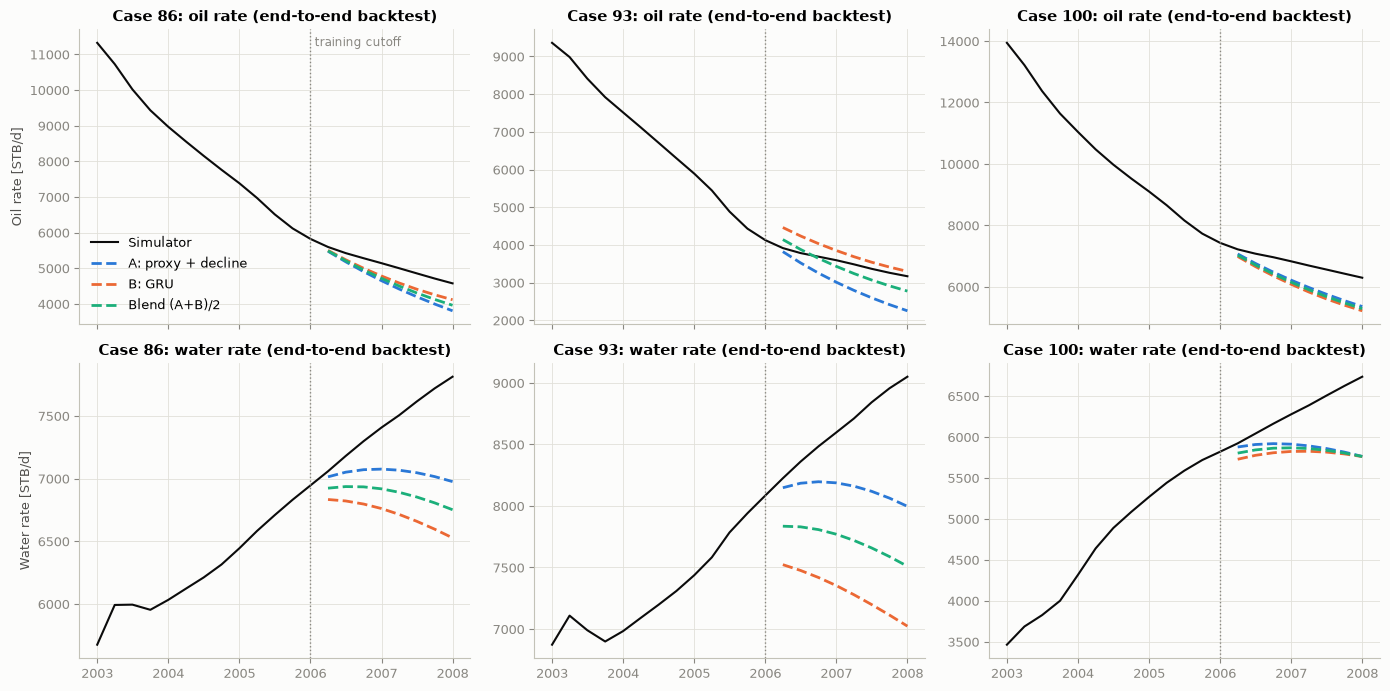

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
show = TEST_CASES[[0, 7, 14]]
win = slice(CUTOFF - 12, None)
for col, case in enumerate(show):
    k = list(TEST_CASES).index(case)
    for row, (v, lab) in enumerate([(0, 'Oil rate [STB/d]'), (2, 'Water rate [STB/d]')]):
        ax = axes[row, col]
        ax.plot(HIST_DATES[win], RATE[case - 1, win, v], color=C['actual'], lw=1.5, label='Simulator')
        ax.axvline(HIST_DATES[CUTOFF], color=C['muted'], lw=1, ls=':')
        for key, color in [(('End-to-end', 'A: proxy + decline'), C['A']), (('End-to-end', 'B: GRU'), C['B']),
                           (('End-to-end', 'Blend (A+B)/2'), C['blend'])]:
            ax.plot(BT_DATES, bt_test_out[key][0][k, :, v], color=color, ls='--', label=key[1])
        ax.set_title(f'Case {case}: {lab.split(" [")[0].lower()} (end-to-end backtest)')
        ax.set_ylabel(lab if col == 0 else '')
axes[0, 0].legend(loc='lower left')
axes[0, 0].annotate('training cutoff', (HIST_DATES[CUTOFF], axes[0, 0].get_ylim()[1]), xytext=(3, -12),
                    textcoords='offset points', color=C['muted'], fontsize=8.5)
fig.tight_layout()
savefig(fig, '05_backtest_examples_test')
plt.show()

**What it shows:** The end-to-end backtest for three test cases. The models only see data up to 2006-01-01 (dotted
line) and forecast the next 8 quarters from the parameters alone. Black is the simulator's true result; dashed lines
are Approach A (blue), Approach B (orange) and their average (green).

**Findings:**
- **Oil:** all three methods follow the decline. Which one is closest changes from case to case.
- **Water:** every method predicts too little water, because the true water rate keeps rising. Approach A (blue) is
  the closest in all three cases.
- The GRU's water rate bends downwards straight after the cutoff. This is not physically plausible while the water
  cut is still rising.
- Over all test cases (tables above), Approach A has the lowest end-to-end error on 2008 cumulatives: 1.50 % against
  1.68 % for the GRU. The same holds on the validation cases (1.54 % against 1.78 %), which is where the choice is
  made.

## 8. Final models: retrain on the full history and forecast 2008 → 2028

The backtest chose the method. The final models are retrained on **all** history up to 2008-01-01. The history proxy
from Section 5 is reused as it is, and the GRU is retrained with 5 new seeds on the full period.

In [14]:
final_gru = [train_gru(T_END, SEED + 100 + s)[0] for s in range(N_SEEDS)]
torch.save([m.state_dict() for m in final_gru], MODEL_DIR / 'gru_ensemble.pt')
_ = joblib.dump({'WINDOW': WINDOW, 'CUM_CORR': CUM_CORR, 'GOR_TRAIN': GOR_TRAIN, 'T0': T0,
             'scales': dict(Q=Q_SCALE, NP=NP_SCALE, WP=WP_SCALE, LQL_MU=LQL_MU, LQL_SD=LQL_SD)},
            MODEL_DIR / 'forecast_config.joblib')

FORECAST_METHODS = ('A: proxy + decline', 'B: GRU', 'Blend (A+B)/2')
e2e_rank = summarize(bt_val).xs('End-to-end', level=0)['Final cum APE %']
FORECAST_METHOD = e2e_rank.idxmin()
print('End-to-end validation backtest, final-cum APE % by method:', e2e_rank.to_dict())
print(f'Forecast method selected on validation: {FORECAST_METHOD}')


def forecast_from_params(p, method=None, return_history=False):
    """THE prediction API for downstream steps (history matching, deliverable).
    p: DataFrame with PARAM_COLS (one row per candidate). Returns rates & cumulatives at FC_DATES, shape (n, 80, 3)."""
    method = method or FORECAST_METHOD
    assert method in FORECAST_METHODS, f'method must be one of {FORECAST_METHODS}'
    x = x_scaler.transform(make_features(p))
    r_hist, c_hist = hist_proxy.predict(x)
    rA, cA, _ = decline_forecast(r_hist, c_hist, HIST_DATES, FC_DATES, WINDOW)
    if method == FORECAST_METHODS[0]:
        r, c = rA, cA
    else:
        xt = torch.tensor(x, dtype=torch.float32)
        s0 = torch.tensor(to_state(RATE[TRAIN_IDX, T0], CUM[TRAIN_IDX, T0]).mean(0, keepdims=True)).repeat(len(x), 1)
        all_dates = HIST_DATES[T0:].append(FC_DATES)
        days = torch.tensor(np.diff(all_dates.values).astype('timedelta64[D]').astype(np.float32))
        with torch.no_grad():
            runs = [m(xt, s0, days) for m in final_gru]
        qo, qw = np.mean([np.stack([t.numpy() for t in state_rates(rr)], axis=-1) for rr in runs], 0).transpose(2, 0, 1)
        F = len(FC_DATES)
        rh = np.stack([qo[:, 1:-F], GOR_TRAIN * qo[:, 1:-F], qw[:, 1:-F]], axis=-1)
        c_anchor = integrate_cum(rh, np.repeat(CUM[TRAIN_IDX, T0].mean(0)[None], len(x), 0),
                                 HIST_DATES[T0], HIST_DATES[T0 + 1:])[:, -1]
        rB = np.stack([qo[:, -F:], GOR_TRAIN * qo[:, -F:], qw[:, -F:]], axis=-1)
        cB = integrate_cum(rB, c_anchor, HIST_DATES[-1], FC_DATES)
        r, c = (rB, cB) if method == FORECAST_METHODS[1] else ((rA + rB) / 2, (cA + cB) / 2)
    return (r, c, r_hist, c_hist) if return_history else (r, c)


# Forecast every validation + test case with all three methods (parameters only) for comparison
eval_cases = np.concatenate([VAL_CASES, TEST_CASES])
fc = {m: forecast_from_params(params.loc[eval_cases], m) for m in FORECAST_METHODS}
eur = pd.DataFrame({m: [c[:, -1, v].mean() / 1e6 for v in range(3)] for m, (_, c) in fc.items()},
                   index=[f'Mean {v} cum @ 2028 [MM{u}]' for v, u in zip(VARS, CUM_UNITS)])
display(eur.round(2))

End-to-end validation backtest, final-cum APE % by method: {'A: proxy + decline': 1.541, 'B: GRU': 1.784, 'Blend (A+B)/2': 1.618}
Forecast method selected on validation: A: proxy + decline


,A: proxy + decline,B: GRU,Blend (A+B)/2
Mean oil cum @ 2028 [MMSTB],54.56,61.63,58.10
Mean gas cum @ 2028 [MMMSCF],19.82,22.39,21.11
Mean water cum @ 2028 [MMSTB],84.18,60.24,72.21


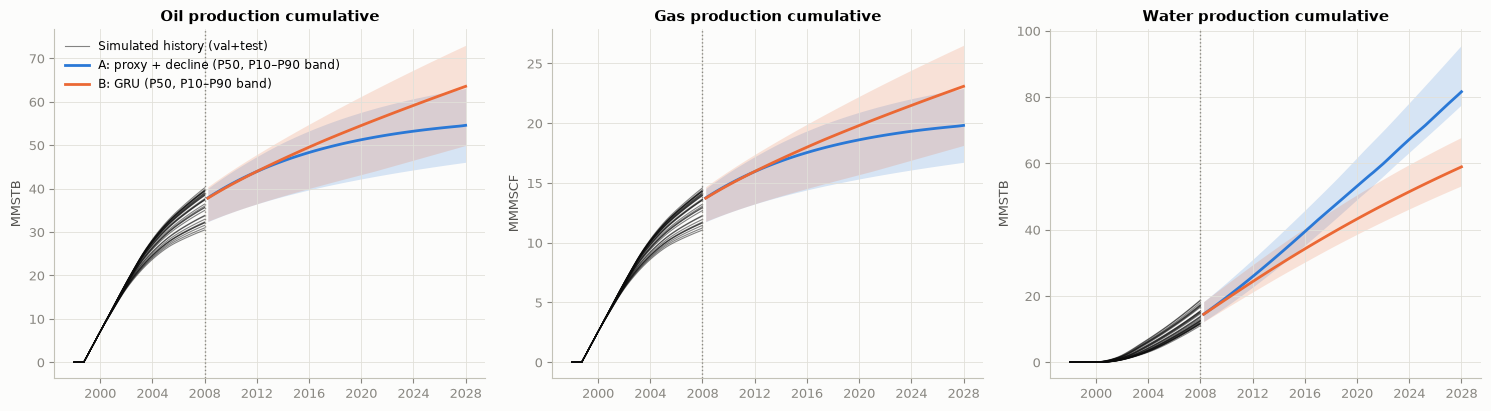

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for v, ax in enumerate(axes):
    for j, c in enumerate(eval_cases):
        ax.plot(HIST_DATES, CUM[c - 1, :, v] / 1e6, color=C['actual'], lw=0.8, alpha=0.5,
                label='Simulated history (val+test)' if j == 0 else None)
    for m, color in [('A: proxy + decline', C['A']), ('B: GRU', C['B'])]:
        cm = fc[m][1][..., v] / 1e6
        ax.fill_between(FC_DATES, np.percentile(cm, 10, 0), np.percentile(cm, 90, 0), color=color, alpha=0.18, lw=0)
        ax.plot(FC_DATES, np.median(cm, 0), color=color, label=f'{m} (P50, P10–P90 band)')
    ax.axvline(HIST_DATES[-1], color=C['muted'], lw=1, ls=':')
    ax.set_title(f'{VARS[v].title()} production cumulative')
    ax.set_ylabel(f'MM{CUM_UNITS[v]}')
axes[0].legend(loc='upper left', fontsize=8.5)
fig.tight_layout()
savefig(fig, '06_forecast_2028_val_test')
plt.show()

**What it shows:** The cumulative forecast to 2028 for the 30 validation and test cases, from their parameters only.
Black: simulated history to 2008. Lines: the middle case (P50) of Approach A (blue) and Approach B (orange). Shaded
bands: P10–P90 across the cases.

**Findings:**
- The two approaches agree for the first few years, then move apart.
- By 2028 (average over the 30 cases), Approach A gives 54.6 MMSTB oil and 84.2 MMSTB water. Approach B gives
  61.6 MMSTB oil and 60.2 MMSTB water. The GRU predicts more oil and much less water.
- Approach A's water keeps rising, in line with the rising water cut in the history. The GRU's water flattens, the
  same downward drift seen in the backtest.
- Approach A is used, because it had the lowest backtest error. The large gap between the two approaches shows that
  the long-range forecast, especially for water, is uncertain.

## 9. Summary

**Outputs**
- **History proxy** (`outputs/models/history_proxy.joblib`): parameters → 1998–2008 rates and cumulatives in
  milliseconds. Notebook 02 uses the same model (code in `pipeline/proxy.py`) for history matching.
- **Forecast method:** decline curves (Approach A), with the decline window chosen on the validation backtests.
  Notebook 02 improves it further by starting the forecast from the last observed rates.
- **Charts** in `outputs/figures/01_Proxy_Model/`.

**Key findings**
- The Gaussian Process proxy reproduces the simulator almost exactly on unseen cases (well under 1 % error on
  cumulatives), so it can safely replace the simulator during history matching.
- **The porosity multiplier has the most impact** on both oil and water produced to 2008. Permeability comes second
  for oil and aquifer size second for water. Fault transmissibility barely matters. So history matching should pin
  down porosity well and fault transmissibility poorly.
- In the backtest, decline curves (A) beat the GRU (B) end to end. The GRU's water rate drops right after the cutoff,
  which is not physically plausible while the water cut is still rising.

**Limitations**
- There is no simulator data after 2008. The backtest checks only 2 years ahead, while the forecast runs 20 years, so
  the gap between A and B is a sign of real forecast uncertainty.
- The biggest forecast risk is the **future liquid-rate (well-control) schedule**, not the reservoir. Liquid rate
  changed between 2003 and 2006 for operational reasons, and no method can predict such changes. Approach A assumes the
  2006–2008 liquid trend continues.
- Approach B is trained on about 36 quarters per case but run for 116, so it can drift over long horizons.